<a href="https://colab.research.google.com/github/akshaybhatt97/365-DAYS-AI-ML-WITH-AKSHAY/blob/main/day_079_time_series_basics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 79/365 — Time Series Basics
## What changes when the order of data matters?

A **time series** is data recorded in time order.

Examples:
- daily sales
- website traffic
- CPU usage
- sensor readings
- monthly revenue

The key difference from ordinary tabular ML:

> **Time order matters.**


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


## 1. Create a simple daily time series


In [2]:
rng=np.random.default_rng(42)

dates=pd.date_range(
    start="2026-01-01",
    periods=180,
    freq="D"
)

trend=np.linspace(100,160,len(dates))
weekly=12*np.sin(2*np.pi*np.arange(len(dates))/7)
noise=rng.normal(0,5,len(dates))

demand=trend+weekly+noise

ts=pd.DataFrame({
    "date":dates,
    "demand":demand
})

ts.head()


,date,demand
0,2026-01-01,101.523585
1,2026-01-02,104.517253
2,2026-01-03,116.121782
3,2026-01-04,110.915015
4,2026-01-05,86.379001


## 2. Plot the series


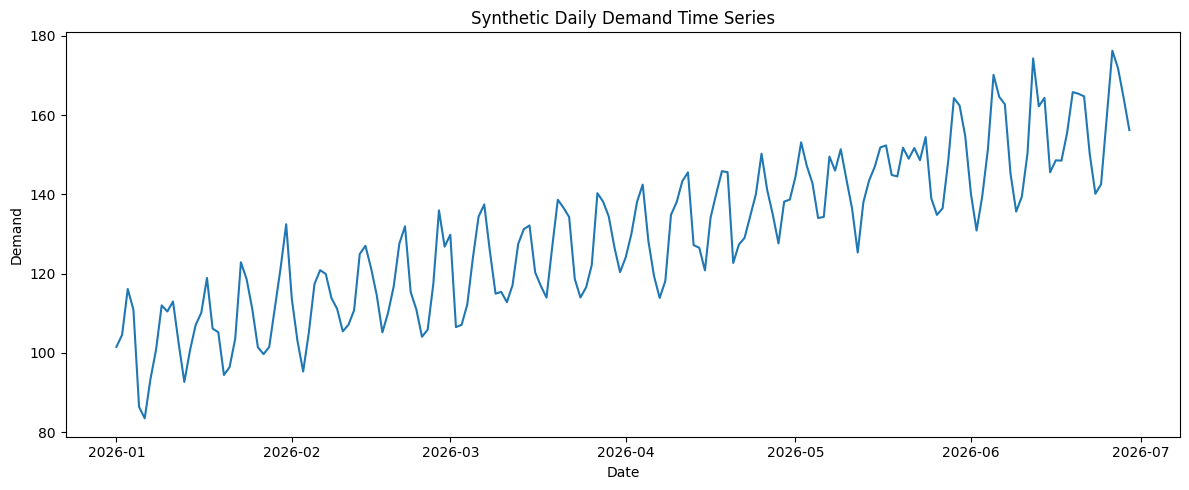

In [3]:
plt.figure(figsize=(12,5))
plt.plot(ts["date"],ts["demand"])
plt.xlabel("Date")
plt.ylabel("Demand")
plt.title("Synthetic Daily Demand Time Series")
plt.tight_layout()
plt.show()


## 3. Core components

### Trend
Long-term increase or decrease.

### Seasonality
A repeating pattern, such as weekly or yearly behavior.

### Noise
Random variation that is difficult to predict.


## 4. Smooth the series with a moving average


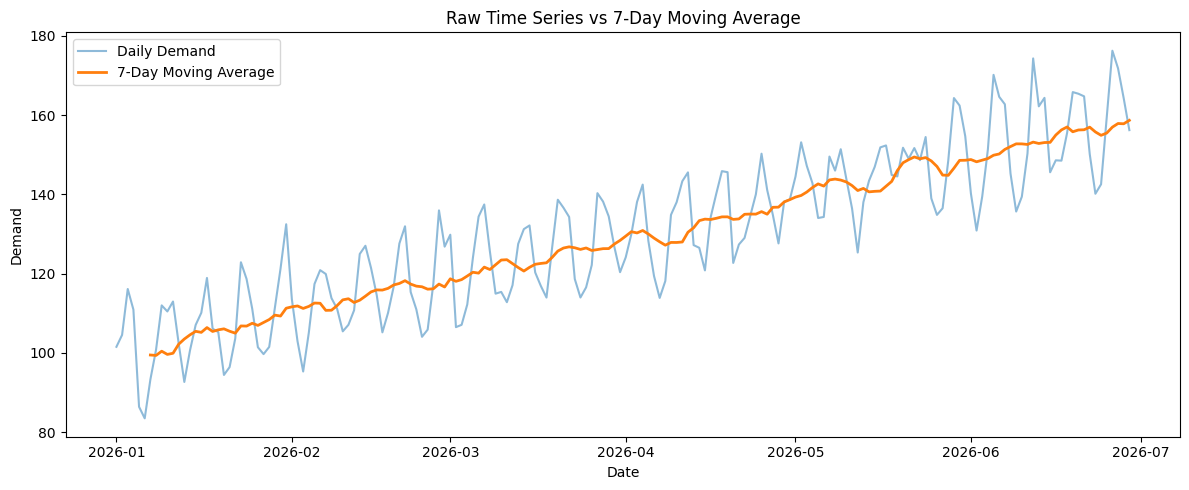

In [4]:
ts["7_day_moving_average"]=(
    ts["demand"]
    .rolling(window=7)
    .mean()
)

plt.figure(figsize=(12,5))
plt.plot(ts["date"],ts["demand"],alpha=0.5,label="Daily Demand")
plt.plot(ts["date"],ts["7_day_moving_average"],linewidth=2,label="7-Day Moving Average")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.title("Raw Time Series vs 7-Day Moving Average")
plt.legend()
plt.tight_layout()
plt.show()


## 5. Lag features

A lag uses a past value as a feature.

`lag_1` = yesterday's value

`lag_7` = value from 7 days ago


In [5]:
ts["lag_1"]=ts["demand"].shift(1)
ts["lag_7"]=ts["demand"].shift(7)

display(
    ts[["date","demand","lag_1","lag_7"]]
    .head(12)
    .round(2)
)


,date,demand,lag_1,lag_7
0,2026-01-01,101.52,NaN,NaN
1,2026-01-02,104.52,101.52,NaN
2,2026-01-03,116.12,104.52,NaN
3,2026-01-04,110.92,116.12,NaN
4,2026-01-05,86.38,110.92,NaN
5,2026-01-06,83.47,86.38,NaN
6,2026-01-07,93.27,83.47,NaN
7,2026-01-08,100.77,93.27,101.52
8,2026-01-09,111.98,100.77,104.52
9,2026-01-10,110.45,111.98,116.12


## 6. Autocorrelation

A time series often depends on its own past.

This is called **autocorrelation**.


In [6]:
print(
    "Lag-1 autocorrelation:",
    round(ts["demand"].autocorr(lag=1),3)
)

print(
    "Lag-7 autocorrelation:",
    round(ts["demand"].autocorr(lag=7),3)
)


Lag-1 autocorrelation: 0.887
Lag-7 autocorrelation: 0.948


## 7. Why random train/test split can be wrong

In ordinary ML, rows are often shuffled.

In time series, that can leak future information into training.

The safer pattern is:

`Past → Train`

`Future → Test`


In [7]:
split_index=int(len(ts)*0.8)

train=ts.iloc[:split_index].copy()
test=ts.iloc[split_index:].copy()

print("Train:",train["date"].min(),"to",train["date"].max())
print("Test:",test["date"].min(),"to",test["date"].max())


Train: 2026-01-01 00:00:00 to 2026-05-24 00:00:00
Test: 2026-05-25 00:00:00 to 2026-06-29 00:00:00


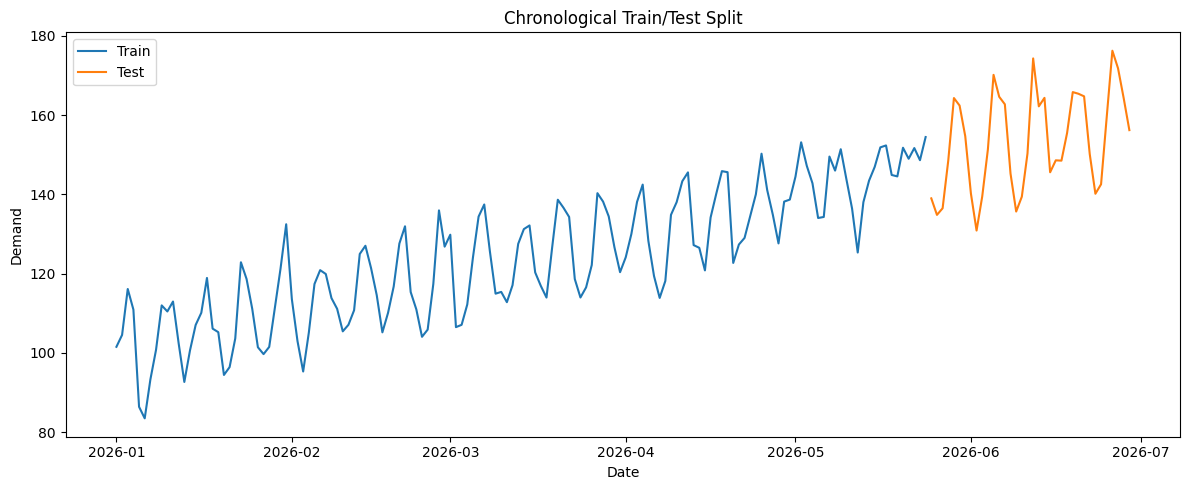

In [8]:
plt.figure(figsize=(12,5))
plt.plot(train["date"],train["demand"],label="Train")
plt.plot(test["date"],test["demand"],label="Test")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.title("Chronological Train/Test Split")
plt.legend()
plt.tight_layout()
plt.show()


## Enterprise intuition

Time-series problems appear in:
- demand forecasting
- inventory planning
- CPU / latency forecasting
- transaction-volume forecasting
- sensor monitoring
- staffing and workload forecasting


## What does this teach?

- Time-series data has temporal order.
- Trend captures long-term movement.
- Seasonality captures repeating patterns.
- Noise captures random variation.
- Lag features use historical values.
- Moving averages smooth short-term fluctuations.
- Random splitting can create leakage.
- Evaluation must respect chronology.

> **In normal tabular ML, rows can often be shuffled. In time series, yesterday and tomorrow are not interchangeable.**


## References

- https://pandas.pydata.org/docs/user_guide/timeseries.html
- https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html
- https://otexts.com/fpp3/
